In Chapter 19, we trained a small transformer on the Rome electricity load. With 952 weights and about 100 days of training data, it did not learn to look at the load one week earlier, and we closed with two remedies: give the network that information directly, or train it on much more data, for example on many series at once. **Foundation models** take the second remedy to its limit. A foundation model for time series is a large network, usually a transformer, that is pretrained once, by its developer, on billions of observations from a very large number of series of every kind: electricity, traffic, sales, weather, web traffic and many more. It is then applied to a new series as it is, without any training on that series: we hand it the recent history, and it returns a forecast.

This chapter comes in two parts. In this first part, we see what foundation models are and how they differ from the models of the earlier chapters, illustrate the idea behind them, transfer learning, with a small experiment, and survey the main models: how they turn a series into tokens, which transformer architecture they use and what kind of forecast they return. In the second part, Chapter 20b, we call several of them from Python, with PyTorch, and forecast the Rome load of Chapters 16 to 19 without training anything.

# Learning objectives

By the end of this lecture, you should be able to

1. explain what a foundation model is, and how pretraining, zero-shot forecasting and fine-tuning differ from the task-specific models of the earlier chapters;
2. write forecasting as the estimation of a conditional distribution, explain transfer learning, and carry out a small transfer-learning experiment;
3. describe the main time series foundation models, TimeGPT, Lag-Llama, TimesFM, Tiny Time Mixers, Moirai and Chronos, by their architecture, their tokens, their output and their support for covariates;
4. explain the three ways of turning a series into tokens (quantized values, patches and lag features) and why every model scales the series first;
5. weigh the advantages of foundation models against their limits.

# Setup

Modules and functions used in this lecture.

| Module | Used for |
|---|---|
| `numpy` | arrays, `lib.stride_tricks.sliding_window_view` -- windows of a series |
| `pandas` | `read_csv`, `DataFrame` |
| `matplotlib.pyplot` | `subplots`, `plot` |
| `sklearn.neural_network` | `MLPRegressor` -- the network of Chapter 16, pretrained on many series |
| `statsmodels.tsa.api` | `ExponentialSmoothing` -- the Holt-Winters model of Chapter 6, as a benchmark |
| `time` | `perf_counter` -- timing the fits |

This part needs no deep-learning library. PyTorch enters in Chapter 20b.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.neural_network import MLPRegressor
from statsmodels.tsa.api import ExponentialSmoothing

Self-defined functions carried over from earlier chapters: the run-sequence plot (Chapter 4) and the MSE (Chapter 6).

In [2]:
def run_sequence_plot(y, x=None, title="", xlabel="time", ylabel="value",
                      ax=None, figsize=(9, 3), color="blue", **kwargs):
    "Plot a series against time and return the axes."
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    if x is None:
        x = getattr(y, "index", np.arange(len(y)))
    ax.plot(x, y, color=color, lw=1, **kwargs)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(alpha=0.3)
    return ax


def mse(observations, estimates):
    "Mean squared error between two equal-length sequences."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    if observations.shape != estimates.shape:
        raise ValueError(f"shape mismatch: {observations.shape} vs {estimates.shape}")
    return np.mean((observations - estimates) ** 2)

New self-defined function: the Mean Absolute Error (MAE), which we use for the airline passengers, because it is in the units of the series.

In [3]:
def mae(observations, estimates):
    "Mean absolute error between two equal-length sequences."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    if observations.shape != estimates.shape:
        raise ValueError(f"shape mismatch: {observations.shape} vs {estimates.shape}")
    return np.mean(np.abs(observations - estimates))

---

# From task-specific models to foundation models

Every model of the earlier chapters was **task-specific**: we chose it for one series and estimated its parameters from that series alone. ARIMA, exponential smoothing and Prophet are fitted to the history of the series they forecast, and even the neural networks of Chapters 16 to 19 were trained on windows cut from the first 2,700 hours of a single load series. A task-specific model knows nothing about any other series, and the shorter the history, the less it can learn: this is what held back the Long Short-Term Memory (LSTM) network and the transformer of Chapters 18 and 19.

Since 2018, a different way of building models has transformed Natural Language Processing (NLP). Bidirectional Encoder Representations from Transformers (BERT, Devlin et al., 2019) and the Generative Pre-trained Transformer (GPT, Radford & Narasimhan, 2018) were first **pretrained** on very large amounts of unlabelled text and then **adapted** to specific tasks, such as classification or question answering, with a little extra training, called **fine-tuning**. Pretraining is self-supervised: the targets come from the data themselves, for example the next word of a sentence, so no human labelling is needed, and the amount of usable data is enormous. GPT-3 (Brown et al., 2020) showed how far this goes: a large enough model performs new tasks from a few examples given in its input, or from none at all. Bommasani et al. (2021) named such models **foundation models**: models trained on broad data at scale that can be adapted to a wide range of downstream tasks. The idea spread to computer vision, with the Vision Transformer (ViT, Dosovitskiy et al., 2021), and to science, with AlphaFold for protein structures (Jumper et al., 2021).

For time series, Oreshkin et al. (2021) showed early on that the N-BEATS network, trained on the series of the M4 forecasting competition, could forecast series from other data sets without retraining. Since 2023, a wave of pretrained time series models has followed, from Google, Amazon, Salesforce, IBM, the start-up Nixtla and several universities. They are used in three ways:

- **zero-shot**: the model is applied as it is, with only the history of the new series as input;
- **fine-tuning**: the pretrained weights are trained for a few more steps on the new series or data set;
- **in-context**: extra inputs are given at forecast time, such as related series or covariates, which the model reads without changing its weights.

The table places foundation models next to the models of the earlier chapters.

| | Trained on | Trained when | Examples |
|---|---|---|---|
| **Local** model | the history of one series | for every series | ARIMA, exponential smoothing, Prophet, the networks of Chapters 16 to 19 |
| **Global** model | many series of one data set | once for the data set | N-BEATS, DeepAR, the gradient-boosted trees of a forecasting competition |
| **Foundation** model | very many series from many domains | once, by the developer | TimeGPT, Chronos, TimesFM, Moirai |

Compared with task-specific models, foundation models promise three advantages:

- **Ease of use.** A pretrained model is applied to a new series directly, without choosing orders, seasonal periods or network architectures, and without training.
- **Lower computational requirements.** The expensive training is done once, by the developer; the user only runs the model forward, which takes seconds for thousands of series on a graphics card.
- **Accuracy with limited data.** A model that has seen many series has learned general patterns, such as daily and weekly cycles, trends and level shifts, that a model fitted to a short series cannot learn from it alone.

The field is young, and how far these promises hold is still debated; we come back to the limits at the end of the chapter.

---

# Transfer learning

Foundation models rest on the ability to generalize across domains, to tasks that were not seen during training. **Transfer learning** is the capacity to apply knowledge gleaned from one task to a new one.

A forecasting model is a function $f_\theta: X \mapsto Y$ from a feature space $X$ to the space $Y$ of the dependent variable. We take $X = \{y_{[0:t]},\, x_{[0:t+h]}\}$ and $Y = \{y_{[t+1:t+h]}\}$, where $h$ is the forecast horizon, $y$ the target series and $x$ the exogenous covariates, known up to the end of the horizon. The forecasting task is to estimate the conditional distribution

$$P\big(y_{[t+1:t+h]} \mid y_{[0:t]},\, x_{[0:t+h]}\big) = f_\theta\big(y_{[0:t]},\, x_{[0:t+h]}\big). \tag{1}$$

Every model of this course is a special case. ARIMA is a function $f_\theta$ with a handful of parameters $\theta$, estimated from one series. Transfer learning estimates $\theta$ on a **source** data set, usually large, and uses $f_\theta$ on a **target** data set that played no part in the training. The bet of a foundation model is that one $\theta$, learned from a large and diverse source, works for target series that the model has never seen. As for language models, the accuracy improves with the size of the model and of the training set, according to empirical **scaling laws**, and the source must be diverse in breadth (domains and frequencies) and in depth (long series), so that the model meets every kind of pattern during training.

## Transfer learning in miniature

We illustrate the idea with a small example. We pretrain the Multi-Layer Perceptron (MLP) of Chapter 16 on the 152 monthly turnover series of Australian retail, the data set of Chapter 13, and then use it to forecast the monthly number of international airline passengers from 1949 to 1960, a series it never sees during training. The network reads 60 months, five years, and forecasts the next 12 months at once.

The source series are of very different sizes, from a few million to several thousand million Australian dollars per month, and the target is in thousands of passengers. As every foundation model does, we therefore **scale** each window before the network sees it: we divide the 60 input values and the 12 target values by the mean of the 60 inputs, the **mean scaling** of Chronos. The network learns to forecast shapes, not levels, and its forecasts are multiplied back by the mean of the input window. We cut a window at every month of every series.

In [4]:
retail = pd.read_csv("data/aus_retail.csv", parse_dates=["Month"])
air = pd.read_csv("data/air_passengers.csv", parse_dates=["ds"]).set_index("ds")["y"]

context_len, horizon = 60, 12
inputs, targets = [], []
for _, series in retail.groupby("Series ID"):
    values = series.sort_values("Month")["Turnover"].to_numpy(dtype=float)
    if len(values) < context_len + horizon:
        continue
    windows = sliding_window_view(values, context_len + horizon)
    scale = windows[:, :context_len].mean(axis=1, keepdims=True)      # mean of the 60 inputs
    inputs.append(windows[:, :context_len] / scale)
    targets.append(windows[:, context_len:] / scale)
X_source, Y_source = np.vstack(inputs), np.vstack(targets)
print(f"source: {retail['Series ID'].nunique()} retail series -> {X_source.shape[0]:,} windows of "
      f"{context_len} inputs and {horizon} targets")
print(f"target: airline passengers, {air.index[0]:%Y-%m} to {air.index[-1]:%Y-%m}, {len(air)} months")

source: 152 retail series -> 53,818 windows of 60 inputs and 12 targets
target: airline passengers, 1949-01 to 1960-12, 144 months


We pretrain three networks with two hidden layers of 128 units, with three seeds, and average their forecasts. With `early_stopping=True`, 10% of the windows are held out, and the training of each network stops when its score on them no longer improves.

In [5]:
start = time.perf_counter()
networks = [MLPRegressor(hidden_layer_sizes=(128, 128), early_stopping=True, max_iter=200,
                         random_state=seed).fit(X_source, Y_source) for seed in range(3)]
print(f"3 networks pretrained in {time.perf_counter() - start:.0f} s; "
      f"epochs: {[net.n_iter_ for net in networks]}")


def pretrained_forecast(history):
    "Zero-shot forecast of the next 12 months from the last 60 values of `history`."
    context = np.asarray(history[-context_len:], dtype=float)
    scale = context.mean()
    return np.mean([net.predict((context / scale)[None])[0] for net in networks], axis=0) * scale

3 networks pretrained in 133 s; epochs: [49, 52, 41]


We forecast each of the years 1958, 1959 and 1960 from the history up to the December before, without any training on the passenger series, and compare with two benchmarks that use only the passenger history: the seasonal naive forecast, which repeats the last 12 months, and the Holt-Winters model of Chapter 6, with an additive trend and a multiplicative seasonality, fitted to the passenger history before each forecast.

MAE (thousands of passengers)
      MLP, zero-shot  seasonal naive  Holt-Winters
year                                              
1958            14.3            12.6          15.6
1959            38.2            47.3          20.2
1960            22.1            47.8          10.3
mean            24.9            35.9          15.4


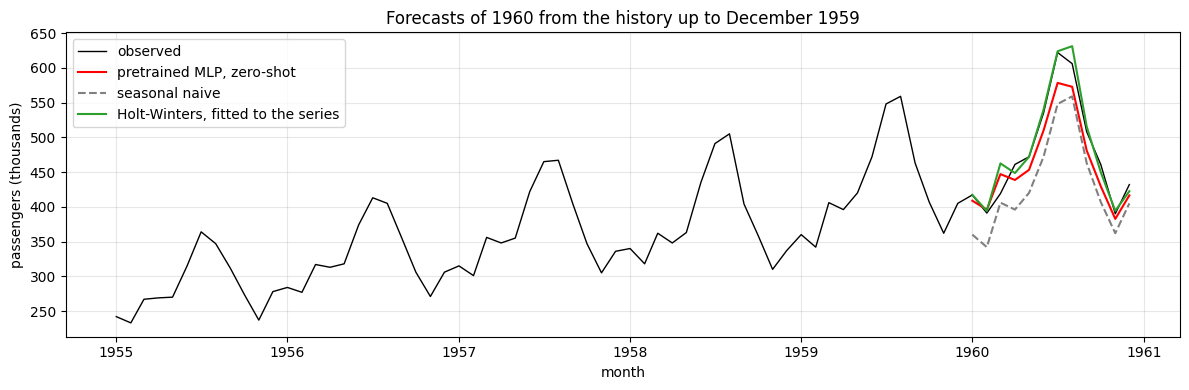

In [6]:
rows, forecasts = [], {}
for year in [1958, 1959, 1960]:
    history = air[air.index.year < year].to_numpy(dtype=float)
    actual = air[air.index.year == year].to_numpy(dtype=float)
    forecasts[year] = {
        "MLP, zero-shot": pretrained_forecast(history),
        "seasonal naive": history[-12:],
        "Holt-Winters": ExponentialSmoothing(
            history, trend="add", seasonal="mul", seasonal_periods=12,
            initialization_method="estimated").fit().forecast(12),
    }
    rows.append({"year": year, **{name: mae(actual, fc) for name, fc in forecasts[year].items()}})
table = pd.DataFrame(rows).set_index("year")
table.loc["mean"] = table.mean()
print("MAE (thousands of passengers)")
print(table.round(1))

ax = run_sequence_plot(air["1955":], color="black", figsize=(12, 4), label="observed",
                       xlabel="month", ylabel="passengers (thousands)",
                       title="Forecasts of 1960 from the history up to December 1959")
dates = air["1960"].index
labels = ["pretrained MLP, zero-shot", "seasonal naive", "Holt-Winters, fitted to the series"]
for fc, label, color in zip(forecasts[1960].values(), labels, ["red", "gray", "tab:green"]):
    ax.plot(dates, fc, color=color, lw=1.5, ls="--" if label == "seasonal naive" else "-", label=label)
ax.legend(); plt.tight_layout(); plt.show()

The networks have never seen an airline passenger, and they were pretrained on retail sales in another country, in another currency and another decade. Yet their forecast of 1960 has the right shape: the peak in July and August, the trough in November and the growth over the previous year, which the seasonal naive forecast misses. Over the three years, the zero-shot forecast has a mean absolute error of 24.9 thousand passengers, against 35.9 for the seasonal naive forecast. It is slightly worse than the seasonal naive forecast in 1958, a year in which the traffic barely grew (14.3 against 12.6), and much better in 1959 and 1960, when it grew strongly again (38.2 against 47.3, and 22.1 against 47.8). What the networks learned from retail sales, seasonal patterns that repeat and grow with the level of the series, transfers to air traffic.

The Holt-Winters model, fitted to the passenger series itself, is better still, with a mean of 15.4, and much better in 1960 (10.3 against 22.1), where the pretrained networks underestimate the summer peak. The airline series is the textbook case for a multiplicative Holt-Winters model, with 9 to 11 years of clean history before each forecast, and a model chosen for it is hard to beat; only in 1958 is the zero-shot forecast better (14.3 against 15.6). This is a fair picture of zero-shot forecasting: with no fitting at all, it gives a sensible forecast that beats the simple benchmark, but a well-chosen model of the series itself can still win. Real foundation models differ from our small experiment by orders of magnitude in the size and the diversity of the source data and in the size of the network, and their promise is that scale closes this gap. Chapter 20b tests it on the Rome load.

---

# Overview of foundation models

Foundation models are a paradigm shift in forecasting: one pretrained model is applied to a wide range of series without data set-specific training. The approach is still young, and it has produced many models in a few years. In chronological order of their first public version, the most cited are

- Time-LLM (Jin et al., 2024),
- TimeGPT-1 (Garza et al., 2023),
- Lag-Llama (Rasul et al., 2024),
- TimesFM (Das et al., 2024),
- Tiny Time Mixers (Ekambaram et al., 2024),
- Moirai (Woo et al., 2024),
- MOMENT (Goswami et al., 2024),
- UniTS (Gao et al., 2024),
- Chronos (Ansari et al., 2024).

The table summarizes them; the terms in its columns are explained below and in the next section.

| Model | Developer | Architecture | Tokens | Output | Covariates | Weights |
|---|---|---|---|---|---|---|
| Time-LLM | Monash University and others | a frozen large language model, reprogrammed | patches, mapped to text prototypes | point | no | open code, trained per data set |
| TimeGPT | Nixtla | encoder-decoder transformer | windows of values | point and conformal intervals | past and future | closed, through an API |
| Lag-Llama | ServiceNow, Mila and others | decoder-only transformer | lag features and date features | Student's $t$ distribution | no | open |
| TimesFM | Google Research | decoder-only transformer | patches | point (later versions: quantiles) | through a regression add-on | open |
| Tiny Time Mixers (TTM) | IBM Research | MLP-Mixer, no attention | patches | point | through fine-tuning | open |
| Moirai | Salesforce | encoder-only transformer | patches of several sizes | mixture of distributions | past and future | open |
| MOMENT | Carnegie Mellon University | encoder-only transformer | patches | reconstruction; a forecast head is fine-tuned | no | open |
| UniTS | Harvard University | transformer with task tokens | patches | several tasks | no | open |
| Chronos | Amazon | encoder-decoder language model (T5) | quantized values | samples from a categorical distribution | no (Chronos-2: yes) | open |

Understanding the core components of the transformer, which we met in Chapter 19, is enough to understand the particularities of each model. We now present the six that are most used in practice.

## TimeGPT

TimeGPT-1 (Garza et al., 2023), from the company Nixtla, was the first widely publicized foundation model for forecasting. It is an **encoder-decoder** transformer, like the original transformer of Vaswani et al.: the encoder processes the input window of historical values, enhanced with **local positional encodings** that tell the model the order of the values, and the decoder uses the encoded information to generate the forecast. Each layer has residual connections and layer normalization, as in the block of Chapter 19, and a final linear layer maps the decoder output to the forecast horizon. Prediction intervals are obtained by conformal prediction, from the model's errors on the most recent part of the history.

TimeGPT was trained on a large collection of publicly available series, over 100 billion data points in total, from finance, economics, demographics, healthcare, weather, Internet of Things (IoT) sensors, energy, web traffic, sales, transport and banking. Its weights are not public: it is offered as a service, through an Application Programming Interface (API) that requires a key, so the data are sent to Nixtla's servers. It accepts exogenous variables, historical and future, and can be fine-tuned through the API.

<img src="media/FoundationModels/timegpt_archi.png" style="width: 100%; display: block; margin: auto;">

<p style="text-align: center;"><em>Architecture of TimeGPT (Garza et al., 2023).</em></p>

For more information, see the [paper](https://arxiv.org/abs/2310.03589) and the [repository](https://github.com/Nixtla/nixtla).

## Lag-Llama

Lag-Llama (Rasul et al., 2024) is a probabilistic univariate model built on the architecture of LLaMA, a family of large language models from Meta. It is a **decoder-only** transformer: there is no encoder, and the model directly generates the forecast, one step at a time, with the causal mask of Chapter 19. Its tokens are **lag features**: the token of time $t$ holds the values of the series at a fixed set of lags, such as 1, 2, 3, 7, 12, 24 or 168 steps back, chosen to cover the seasonal periods of the common frequencies (quarterly, monthly, weekly, daily, hourly, down to the second), together with date features such as the month or the day of the week. To estimate the uncertainty of its predictions, its output is the location, scale and degrees of freedom of a **Student's $t$-distribution**, from which forecasts are sampled. It is small, a few million parameters, and was trained on 27 public data sets.

<img src="media/FoundationModels/lagllama_archi.png" style="width: 45%; display: block; margin: auto;">

<p style="text-align: center;"><em>Architecture of Lag-Llama (Rasul et al., 2024).</em></p>

For more information, see the [paper](https://arxiv.org/abs/2310.08278) and the [repository](https://github.com/time-series-foundation-models/lag-llama).

## TimesFM

TimesFM (Das et al., 2024), from Google Research, is a decoder-only model. It cuts the series into **patches** of 32 values, the tokens of Chapter 19, and embeds each patch with a residual block, a small MLP with a skip connection. Its output patches are longer than its input patches, 128 values, so that it needs fewer auto-regressive steps when the horizon exceeds one output patch. The first version, with 200 million parameters, was trained on about 100 billion time points from Google Trends, Wikipedia page views and synthetic series, and returned point forecasts. TimesFM 2.5 (2025) has 200 million parameters, a context of up to 16,384 values and an optional quantile head for probabilistic forecasts; TimesFM 3.0 (2026) adds multivariate forecasting and covariates, with weights under a non-commercial license.

<img src="media/FoundationModels/timesfm_archi.png" style="width: 75%; display: block; margin: auto;">

<p style="text-align: center;"><em>Architecture of TimesFM (Das et al., 2024).</em></p>

For more information, see the [paper](https://arxiv.org/abs/2310.10688) and the [repository](https://github.com/google-research/timesfm).

## Tiny Time Mixers

Tiny Time Mixers (TTM, Ekambaram et al., 2024), from IBM Research, are deliberately small: from about 1 million parameters, small enough to run on a laptop without a graphics card. They are not transformers. They are built on TSMixer, an **MLP-Mixer** that alternates MLPs across the patches of a series and MLPs across the values within a patch, instead of attention. A family of TTM models covers different context lengths and horizons, each trained for its own combination, and point forecasts are returned. Exogenous variables are supported through fine-tuning, with a channel-mixing decoder.

<img src="media/FoundationModels/ttm_archi.png" style="width: 100%; display: block; margin: auto;">

<p style="text-align: center;"><em>Architecture of Tiny Time Mixers (Ekambaram et al., 2024).</em></p>

For more information, see the [paper](https://arxiv.org/abs/2401.03955) and the [repository](https://github.com/ibm-granite/granite-tsfm).

## Moirai

Moirai (Woo et al., 2024), from Salesforce, is an **encoder-only** transformer trained, like BERT, to reconstruct masked parts of the series: the future is a masked part, to be filled in. It also cuts the series into patches, with a patch size that depends on the frequency of the data, larger for high frequencies, and it handles **any number of variates**: all the variates of a multivariate series, including covariates, are flattened into one sequence of tokens, with an encoding that tells the attention which tokens belong to which variate. It supports past and future exogenous variables. Its output is a **mixture distribution** of four components, a Student's $t$, a negative binomial, a log-normal and a low-variance normal distribution, which gives flexible prediction intervals for very different kinds of series. Moirai comes in three sizes, from 14 to 311 million parameters, and was released with the Large-scale Open Time Series Archive (LOTSA), an open archive of 27 billion observations, at the time the largest open collection of time series for pretraining. Moirai-MoE (2024) and Moirai 2.0 (2025) followed.

<img src="media/FoundationModels/moirai_archi.png" style="width: 100%; display: block; margin: auto;">

<p style="text-align: center;"><em>Architecture of Moirai (Woo et al., 2024).</em></p>

For more information, see the [paper](https://arxiv.org/abs/2402.02592) and the [repository](https://github.com/SalesforceAIResearch/uni2ts).

## Chronos

Chronos (Ansari et al., 2024), from Amazon, is a framework that repurposes a language model for forecasting with as few changes as possible. It **tokenizes** the series: each value is divided by the mean absolute value of the context and then **quantized**, that is, assigned to one of about 4,000 bins, so that the series becomes a sequence of words from a fixed vocabulary of 4,096 tokens. A standard encoder-decoder language model, the Text-to-Text Transfer Transformer (T5) of Google, is then trained on these sequences with the usual cross-entropy loss of language models. Since a language model outputs a probability distribution over its vocabulary, Chronos is a probabilistic model: forecasts are sampled token by token and mapped back to values. The models, from 8 to 710 million parameters, were trained on public data sets and on synthetic series generated from Gaussian processes.

<img src="media/FoundationModels/chronos_archi.png" style="width: 90%; display: block; margin: auto;">

<p style="text-align: center;"><em>Architecture of Chronos (Ansari et al., 2024).</em></p>

Two successors changed the design. **Chronos-Bolt** (2024) replaces quantization by patches and predicts quantiles for a whole horizon of up to 64 steps at once, which makes it much faster. **Chronos-2** (Ansari et al., 2025), with 120 million parameters, is an encoder-only model with a context of up to 8,192 values that reads several series and covariates together, past and future, through a **group attention** layer that lets related series share information.

For more information, see the [paper](https://arxiv.org/abs/2403.07815), the [Chronos-2 paper](https://arxiv.org/abs/2510.15821) and the [repository](https://github.com/amazon-science/chronos-forecasting).

## Other models

Time-LLM (Jin et al., 2024) keeps a large language model frozen and learns, for each data set, a reprogramming layer that maps patches of the series to combinations of word embeddings, plus a text prompt that describes the task; it is not zero-shot. MOMENT (Goswami et al., 2024) and UniTS (Gao et al., 2024) are multi-task models, pretrained for forecasting, classification, anomaly detection and imputation. More recent models include Time-MoE, a mixture of experts with up to 2.4 billion parameters, Sundial, Toto, trained on observability metrics of computer systems, and TiRex, built on the extended LSTM (xLSTM), a successor of the LSTM of Chapter 18. Public leaderboards, such as GIFT-Eval (Aksu et al., 2024) and fev-bench, compare them on common test series and try to keep those series out of their training data.

---

# Turning a series into tokens

Text comes in words; a series comes in numbers, often on very different scales. Every foundation model therefore does two things before its transformer sees the data.

**Scaling.** The context is divided by its mean absolute value (Chronos, Lag-Llama) or standardized with its mean and standard deviation (Chronos-Bolt, TimesFM, Moirai, an operation called **instance normalization**), and the forecast is transformed back at the end. The model sees only the shape of the series, so that one model can serve series of passengers, megawatts or dollars.

**Tokenizing.** The scaled series is then turned into a sequence of tokens, in one of three ways.

- **Quantized values** (Chronos). Each scaled value is assigned to one of $B$ bins of equal width on a fixed interval, and the bin number becomes the token, as a word index in a language model. The vocabulary is fixed, the model is a standard language model, and the forecast is a distribution over the bins.
- **Patches** (TimesFM, Moirai, Tiny Time Mixers, Chronos-Bolt, Chronos-2). Consecutive values are grouped into patches, embedded by a small network, as in Chapter 19. A patch carries more information than a single value, and the sequence of tokens is shorter, which makes attention cheaper: its cost grows with the square of the number of tokens.
- **Lag features** (Lag-Llama). The token of time $t$ is the vector of the values at a fixed set of lags, plus date features, as in the windowed regressions of Chapters 7 and 16.

We tokenize one week of the Rome load in the three ways. For the quantized values, we follow the tokenizer of the original Chronos: the context is divided by its mean absolute value, the 4,093 bin centers are evenly spaced on $[-15, 15]$, and each value gets the number of its closest center, shifted by 2, because tokens 0 and 1 are reserved for padding and the end of the sequence.

mean absolute value: 54.84;  bin width: 0.0073 after scaling, 0.402 in load units
first 8 loads:  [16.59 16.41 15.34 16.13 20.31 22.4  22.98 24.17]
first 8 tokens: [2089 2089 2086 2088 2099 2104 2105 2108]
tokens used by the week: 101 distinct, from 2086 to 2262;  largest decoding error: 0.200


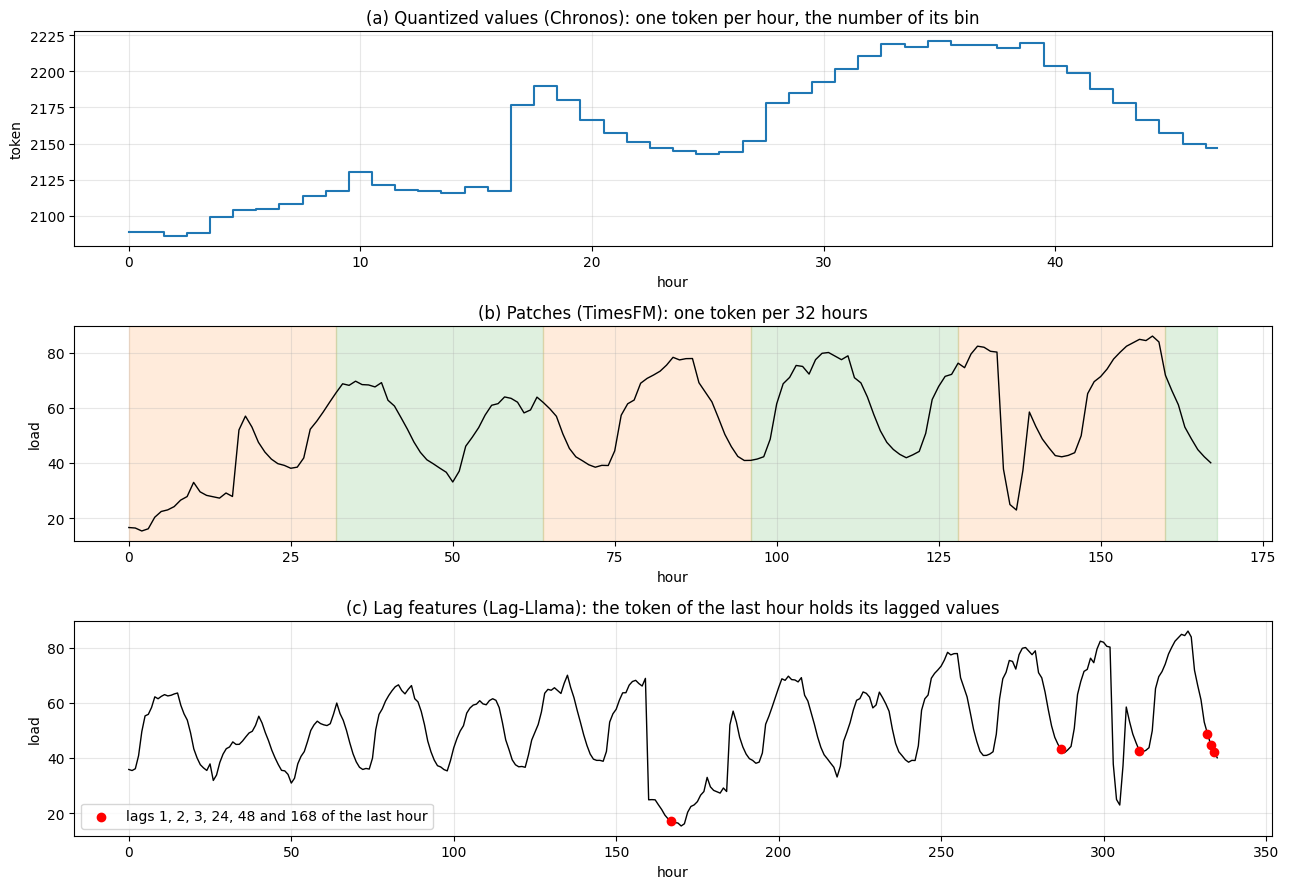

In [7]:
rome = pd.read_csv("data/elec_rome_hourly.csv", index_col="step")["load"].to_numpy()
week = rome[2232:2400]                                 # the last week before the validation period of Chapter 19

centers = np.linspace(-15, 15, 4093)                   # bin centers of Chronos
scale = np.mean(np.abs(week))
scaled = week / scale
tokens = np.argmin(np.abs(scaled[:, None] - centers[None, :]), axis=1) + 2
decoded = centers[tokens - 2] * scale
print(f"mean absolute value: {scale:.2f};  bin width: {centers[1] - centers[0]:.4f} after scaling, "
      f"{(centers[1] - centers[0]) * scale:.3f} in load units")
print("first 8 loads: ", np.round(week[:8], 2))
print("first 8 tokens:", tokens[:8])
print(f"tokens used by the week: {len(np.unique(tokens))} distinct, from {tokens.min()} to {tokens.max()};  "
      f"largest decoding error: {np.max(np.abs(decoded - week)):.3f}")

fig, axes = plt.subplots(3, 1, figsize=(13, 9))
hours = np.arange(48)
axes[0].step(hours, tokens[:48], where="mid", color="tab:blue")
axes[0].set(title="(a) Quantized values (Chronos): one token per hour, the number of its bin",
            xlabel="hour", ylabel="token")
axes[1].plot(np.arange(168), week, color="black", lw=1)
for j in range(0, 168, 32):
    axes[1].axvspan(j, min(j + 32, 168), color="tab:orange" if (j // 32) % 2 == 0 else "tab:green", alpha=0.15)
axes[1].set(title="(b) Patches (TimesFM): one token per 32 hours", xlabel="hour", ylabel="load")
lags = [1, 2, 3, 24, 48, 168]
t = 335
two_weeks = rome[2232 - 168:2400]
axes[2].plot(np.arange(336), two_weeks, color="black", lw=1)
axes[2].scatter([t - l for l in lags], two_weeks[[t - l for l in lags]], color="red", zorder=3,
                label="lags 1, 2, 3, 24, 48 and 168 of the last hour")
axes[2].set(title="(c) Lag features (Lag-Llama): the token of the last hour holds its lagged values",
            xlabel="hour", ylabel="load")
axes[2].legend(loc="lower left")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

After the division by the mean absolute value of the week, 54.84, the load varies between about 0.3 and 1.6, and a bin of width 0.0073 corresponds to 0.40 load units. The week uses only 101 of the 4,093 bins, tokens 2086 to 2262: the scaled values of a series lie in a narrow band around 1, and the wide interval $[-15, 15]$ is there for series with large spikes. Decoding a token back to the center of its bin loses at most half a bin, 0.20 load units, far less than the forecast errors of the earlier chapters. Panel (a) shows the first two days as the model sees them: a sequence of integers, like the word indices of a sentence. A language model knows nothing in advance about the order of its tokens; Chronos has to learn from data that token 2150 lies between tokens 2149 and 2151.

In panel (b), the same week becomes 6 tokens, 5 full patches of 32 hours and a partial one, which TimesFM pads with masked values, where Chronos needs 168 tokens. Panel (c) shows the lag features of the last hour: its own recent past, the same hour one and two days earlier and one week earlier. Such a token already contains the seasonal information that the transformer of Chapter 19 failed to learn.

---

# Architectures and outputs

The models differ in two more choices, both of which we have met before.

**Which part of the transformer.** The original transformer of Vaswani et al. (2017) has an encoder, which reads the input, and a decoder, which generates the output from it. Foundation models use either both or one of them:

- **encoder-decoder** (TimeGPT, Chronos, Chronos-Bolt): the encoder reads the context, and the decoder produces the forecast;
- **decoder-only** (Lag-Llama, TimesFM, Time-MoE): one stack of causal blocks, as in Chapter 19 and in GPT, trained to predict every next token from the ones before it;
- **encoder-only** (Moirai, MOMENT, Chronos-2): one stack of blocks without a causal mask, as in BERT, which fills in the masked tokens of the forecast horizon.

**What comes out.** The forecasts take four forms:

- a **point forecast** (the first TimesFM, TTM), trained with the squared or absolute error;
- **samples** of possible futures, generated one token at a time from a categorical distribution over the bins (Chronos) or from a parametric distribution, a Student's $t$ (Lag-Llama) or a mixture (Moirai), trained by maximum likelihood;
- **quantiles**, for example the 10%, 50% and 90% quantiles of every future value (Chronos-Bolt, Chronos-2, TimesFM 2.5, Moirai 2.0), trained with the quantile loss of the gradient-boosted readout of Chapter 17.

Models that generate one value or one patch at a time and feed it back as input are **auto-regressive**, like the AR models of Chapters 9 and 10; their errors can accumulate over long horizons, and generating samples one token at a time is slow. Models that output the whole horizon at once, as a long output patch or a set of quantiles, make **direct multi-step** forecasts, which are faster. The trend since 2024 has been toward patches, direct multi-step quantile forecasts and support for covariates.

---

# Using foundation models in practice

**Zero-shot.** The simplest use: give the model the history, the horizon and, for a probabilistic model, the quantiles or the number of samples, and read the forecast. There is nothing to fit, so a zero-shot forecast takes minutes to set up and is a strong benchmark for any new forecasting problem.

**Fine-tuning.** The pretrained weights can be trained further on the target data set, with a small learning rate and few steps, so that the model adapts to its particularities without forgetting what it learned in pretraining. With TimeGPT, it is an argument of the forecast call (`finetune_steps`); with Chronos-2, a method of the model (`fit`). Fine-tuning helps most when the target series are unlike the pretraining data, and it brings back the risk of overfitting that zero-shot use avoids.

**Covariates.** Electricity prices depend on load and wind forecasts, sales on prices and promotions, load on temperature and holidays. Most early foundation models were univariate and could not use such information, while the regression models of Chapters 7, 8 and 13 always could. TimeGPT, Moirai and Chronos-2 accept covariates known in the past and in the future, and TimesFM 2.5 combines its forecast with a linear regression on covariates. Covariates are often what separates a good forecast from a mediocre one, so their support matters when choosing a model.

**Evaluation.** A foundation model must be evaluated as any other model, on data it has not seen, with the rolling-origin evaluation of the earlier chapters. One pitfall is specific to them: their pretraining collections contain most public data sets, so a model may have seen the very series, or a copy of it, on which it is evaluated. This **data leakage** inflates published accuracies, and benchmarks such as GIFT-Eval and fev-bench were built to avoid it. On your own, unpublished data, the problem does not arise.

**Limits.** The advantages listed at the start come with costs and open questions.

- **Inference cost.** A forecast from a model with hundreds of millions of parameters costs far more computation than one from ARIMA or exponential smoothing; on a laptop without a graphics card, the slower models take minutes for a few hundred forecasts.
- **Interpretability.** A pretrained transformer has no parameters with a meaning, such as a seasonal coefficient or a smoothing constant, and it cannot explain its forecast.
- **Domain knowledge.** A zero-shot model knows nothing of holidays, tariffs or the physics of the system unless it is given them as covariates.
- **Licenses and privacy.** Weights come under different licenses, some of them non-commercial, and a model behind an API, such as TimeGPT, receives the data.
- **Evidence.** Critical reviews, such as Bergmeir (2024), argue that the gains over well-tuned statistical models smaller and less consistent than the developers' benchmarks suggest.

A sensible practice is to treat a foundation model as one more candidate, compared with the simple benchmarks and the models of the earlier chapters on a hold-out period of your own data. We do exactly that in Chapter 20b.

---

# Further reading

- The benchmark of the foundation models of this chapter by Nixtla, the developer of TimeGPT, in the [nixtla repository](https://github.com/Nixtla/nixtla).
- A review of the current state and future prospects of Large Language Models (LLMs) and foundation models in forecasting: Bergmeir, C. (2024). LLMs and foundational models: not (yet) as good as hoped. *Foresight*, 73.
- A benchmark of foundation models on data kept out of their training, from Salesforce: Aksu, T., et al. (2024). GIFT-Eval: A benchmark for general time series forecasting model evaluation. [arXiv:2410.10393](https://arxiv.org/abs/2410.10393).
- A survey: Liang, Y., et al. (2024). Foundation models for time series analysis: A tutorial and survey. *Proceedings of the 30th ACM SIGKDD Conference*. [arXiv:2403.14735](https://arxiv.org/abs/2403.14735).

---

# Summary

**Foundation model**: a large network, usually a transformer, pretrained once on a very large and diverse collection of series, and applied to new series zero-shot, after fine-tuning, or with extra inputs given in context.

- **Transfer learning.** Forecasting estimates $P(y_{[t+1:t+h]} \mid y_{[0:t]}, x_{[0:t+h]}) = f_\theta(y_{[0:t]}, x_{[0:t+h]})$. A foundation model learns $\theta$ on a source collection and uses it on target series it has never seen. An MLP pretrained on 152 retail series forecast the airline passengers zero-shot with a mean absolute error of 24.9 thousand, against 35.9 for the seasonal naive forecast and 15.4 for a Holt-Winters model fitted to the series.
- **The models.** TimeGPT (Nixtla, encoder-decoder, API), Lag-Llama (decoder-only, lag tokens, Student's $t$), TimesFM (Google, decoder-only, patches), Tiny Time Mixers (IBM, MLP-Mixer, about 1 million parameters), Moirai (Salesforce, encoder-only, any number of variates, mixture output) and Chronos (Amazon, a T5 language model on quantized values), followed by Chronos-Bolt, Chronos-2, TimesFM 2.5 and 3.0 and Moirai 2.0.
- **Tokens.** Every model scales the context first, by its mean absolute value or by instance normalization, and then turns it into tokens: quantized values, patches or lag features. Patches have become the most common choice.
- **Outputs.** Point forecasts, samples from a categorical or parametric distribution, or quantiles; auto-regressive generation or direct multi-step output.
- **In practice.** Zero-shot forecasts are cheap to set up and make strong benchmarks. Fine-tuning and covariates can improve them. Benchmarks may be inflated by data leakage, and the models are costly to run, hard to interpret and blind to domain knowledge not given as covariates.